In [14]:

import pandas as pd

In [15]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [16]:

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # текст из totalcharges 
print(df["TotalCharges"].isna().sum())                                   # проверяет на пропуски 
df["TotalCharges"] = df["TotalCharges"].fillna(0)                       # пропуск -> 0

11


In [18]:
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)     # yes - 1 , no - 0

 Подготовка данных

Убрал столбец customerID: это просто номер клиента, он ничего не говорит о его поведении. Ответ Churn перевёл в числа: 1 — клиент ушёл, 0 — остался.

In [19]:
df["Churn"].value_counts(normalize=True)

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

Баланс классов

Уходит 26,5% клиентов , остаются 73,5%. Классы несбалансированы: ушедших почти в три раза меньше. Поэтому модель, которая всем отвечает "не уйдёт", уже будет права в 73% случаев, и для оценки нельзя смотреть только на долю правильных ответов.

<Axes: xlabel='Contract'>

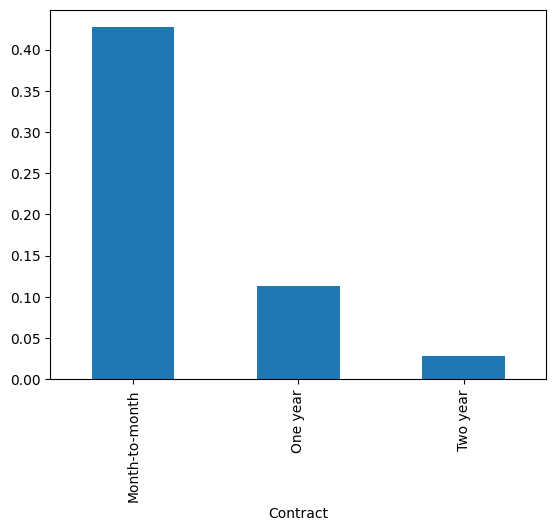

In [20]:
df.groupby("Contract")["Churn"].mean().plot(kind="bar")

Отток по типу контракта

С помесячным контрактом уходит 42,7% клиентов, с контрактом на год — 11,3%, на два года — всего 2,8%. Чем длиннее контракт, тем реже уходят. Клиентов с помесячным контрактом стоит переводить на годовой, например со скидкой.

<Axes: xlabel='PaymentMethod'>

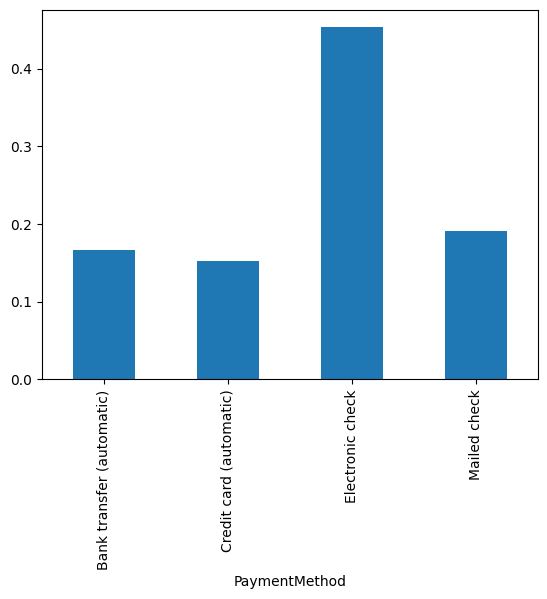

In [21]:
df.groupby("PaymentMethod")["Churn"].mean().plot(kind="bar")

Отток по способу оплаты

Больше всего уходят клиенты, которые платят электронным чеком : 45,3%. У остальных способов отток 15–19%, меньше всего у автоплатежа с карты 15,2%. 

In [22]:
import seaborn as sns

<Axes: xlabel='tenure', ylabel='Count'>

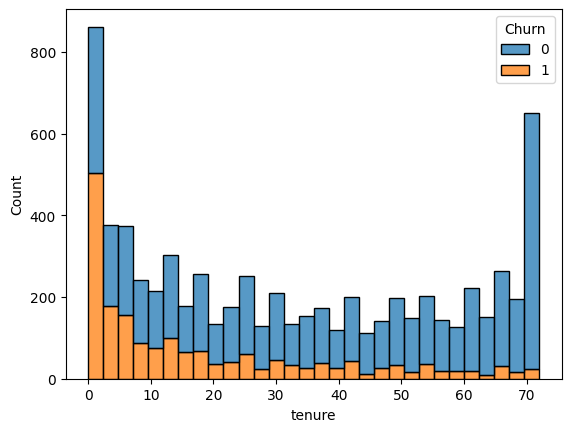

In [23]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")

Отток по стажу

tenure — сколько месяцев клиент пользуется услугами компании. Чаще всего уходят в первый год: в нём отток 47,4%, и на него приходится больше половины всех ушедших 55,5%. Дальше отток падает: 28,7% на втором году и 9,5% у клиентов со стажем больше 4 лет. Удерживать нужно в первую очередь новых клиентов.

In [24]:
from sklearn.model_selection import train_test_split
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)  # признаки, текст → столбцы 0/1. get_dummies  это one-hot encoding. drop_first=True убирает первый вариант, он и так понятен, если остальные нули.
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


Разделение на train и test

Текстовые признаки перевёл в столбцы из 0 и 1 (one-hot encoding), получилось 30 признаков. Данные разделил на train (5 634 клиента, 80%) и test (1 409 клиентов, 20%). stratify=y сохраняет одинаковую долю ушедших в обеих частях, random_state=42 делает разбиение одинаковым при каждом запуске.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test) # ответы 0/1 для test
proba = model.predict_proba(X_test)[:, 1]     # вероятность ухода для каждого клиента
print(pred[:10])            # первые 10 ответов
print(proba[:10].round(2))  # вероятности ухода для них же
print(y_test.values[:10])   # как было на самом деле

[0 1 0 0 0 1 0 0 0 0]
[0.04 0.68 0.06 0.41 0.02 0.6  0.45 0.13 0.   0.39]
[0 0 0 0 0 0 0 0 0 1]


In [26]:
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

pred_03 = (proba > 0.3).astype(int)
print(classification_report(y_test, pred_03))

[[925 110]
 [162 212]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.841778397788628
              precision    recall  f1-score   support

           0       0.89      0.75      0.81      1035
           1       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from catboost import CatBoostClassifier


models = {
    "tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "catboost": CatBoostClassifier(verbose=0, random_state=42),
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="roc_auc")
    print(name, round(scores.mean(), 3), "+/-", round(scores.std(), 3)) # roc-auc , разброс между 5 результатами 

tree 0.818 +/- 0.013
forest 0.824 +/- 0.012
catboost 0.841 +/- 0.013
logreg 0.846 +/- 0.014


In [ ]:
deep = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)   # нет max_depth , переобучение
print("train:", roc_auc_score(y_train, deep.predict_proba(X_train)[:, 1]))
print("test: ", roc_auc_score(y_test,  deep.predict_proba(X_test)[:, 1]))

train: 0.8476371669760115
test:  0.8267043839933865


In [44]:
best = models["catboost"]
best.fit(X_train, y_train)
print(roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]))

0.8393280632411068
